# Tests de robustesse — Niveau 1 (20 foyers) et Niveau 2 (typologie de ménages)

## Objectif

Répliquer, foyer par foyer, les trois tests de robustesse validés dans le TFC
(`06_Data_Degradation_Simulation.html` et la section ablation de `04_UCI_clustering.pdf`) :

1. **Ablation de `is_weekend`** — vérifie que la variable n'est pas redondante avec les 6 autres.
2. **Bruit multiplicatif gaussien** (0% à 30%) — vérifie la résistance à l'imprécision de mesure.
3. **Dégradation par agrégation** (journalier -> hebdomadaire -> mensuel) — simule la perte de
   granularité (données de facturation plutôt que compteur intelligent).

Un **quatrième test, nouveau**, est ajouté spécifiquement pour le Niveau 2 : la robustesse de
la typologie de ménages à la **durée d'historique disponible** (3, 6, 12 mois vs ~2 ans complets)
— test qui reconnecte directement avec la motivation initiale du projet (déploiement partiel de
compteurs intelligents en contexte africain).

AUTEUR : ENANGA DANIEL CHRISTIAN


## Étape 0 : Imports

In [1]:
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
matplotlib.rcParams['figure.dpi'] = 120

BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.insert(0, os.path.join(BASE_DIR, "src"))

from features import (
    FEATURES_FINAL, compute_daily_features, build_daily_features_for_house,
    aggregate_to_frequency, compute_features_from_hourly_profiles, compute_is_weekend_ratio,
)
from clustering_pipeline import reorder_labels_by_size

PROCESSED_DIR = os.path.join(BASE_DIR, "data", "processed", "refit")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
IMAGES_DIR = os.path.join(BASE_DIR, "images", "robustness")
os.makedirs(IMAGES_DIR, exist_ok=True)

RANDOM_STATE = 42
NOISE_LEVELS = [0.0, 0.05, 0.10, 0.15, 0.20, 0.30]
print("Bibliothèques chargées.")


Bibliothèques chargées.


## Étape 1 : Chargement des résultats de référence (Notebook 03 et données nettoyées)

In [2]:
synthesis_path = os.path.join(RESULTS_DIR, "level1_synthesis_table.csv")
labels_path = os.path.join(RESULTS_DIR, "level1_cluster_labels.csv")

df_synthesis = pd.read_csv(synthesis_path) if os.path.exists(synthesis_path) else pd.DataFrame()
df_labels_baseline = pd.read_csv(labels_path, parse_dates=["date"]) if os.path.exists(labels_path) else pd.DataFrame()

# On ne peut rejouer les tests de robustesse (qui reclusterisent avec GMM) que pour les foyers
# où le modèle final retenu est un GMM -- pour les autres, on documente le k retenu et on
# clusterise avec un GMM(k=k_retenu, covariance='full') à titre de comparaison homogène,
# comme le fait le TFC original (qui fixe GMM k=3 pour tous les tests de robustesse).
refit_house_ids = [h for h in df_synthesis["house_id"].unique() if h != "UCI_FR"] if not df_synthesis.empty else []
k_by_house = dict(zip(df_synthesis["house_id"], df_synthesis["k"])) if not df_synthesis.empty else {}

print(f"{len(refit_house_ids)} foyers REFIT disponibles pour les tests de robustesse.")

# Chargement des séries minute nettoyées (nécessaires pour le test de bruit)
clean_series = {}
for house_id in refit_house_ids:
    num = house_id.replace("REFIT_", "")
    path = os.path.join(PROCESSED_DIR, f"house_{num}_clean.csv")
    if os.path.exists(path):
        clean_series[house_id] = pd.read_csv(path, index_col=0, parse_dates=True)["power_kw"]


20 foyers REFIT disponibles pour les tests de robustesse.


## Étape 2 : Ablation de `is_weekend` (Niveau 1, boucle sur les 20 foyers)

Pour chaque foyer, on retire `is_weekend`, on reclusterise (GMM, même k que le modèle final,
covariance `full`, n_init=10), et on compare au clustering original via l'ARI.

In [3]:
FEATURES_WITHOUT_WEEKEND = [f for f in FEATURES_FINAL if f != "is_weekend"]

ablation_rows = []
level1_features_path = os.path.join(PROCESSED_DIR, "level1_features_raw.csv")
df_level1_raw = pd.read_csv(level1_features_path, parse_dates=["date"]) if os.path.exists(level1_features_path) else pd.DataFrame()

if not df_level1_raw.empty and not df_labels_baseline.empty:
    for house_id in refit_house_ids:
        k = int(k_by_house.get(house_id, 3))
        df_h = df_level1_raw[df_level1_raw["house_id"] == house_id].reset_index(drop=True)
        baseline = df_labels_baseline[df_labels_baseline["house_id"] == house_id].reset_index(drop=True)
        if df_h.empty or baseline.empty or df_h.shape[0] != baseline.shape[0]:
            continue

        X_without = StandardScaler().fit_transform(df_h[FEATURES_WITHOUT_WEEKEND].values)
        gmm_without = GaussianMixture(n_components=k, covariance_type="full", random_state=RANDOM_STATE, n_init=10)
        labels_without = reorder_labels_by_size(gmm_without.fit_predict(X_without))

        ari = adjusted_rand_score(baseline["cluster"].values, labels_without)
        ablation_rows.append({"house_id": house_id, "k": k, "ari_ablation_is_weekend": ari})

df_ablation = pd.DataFrame(ablation_rows)
if not df_ablation.empty:
    print(df_ablation.round(4).to_string(index=False))
    print(f"\nARI moyen (ablation is_weekend) : {df_ablation['ari_ablation_is_weekend'].mean():.4f}")
    print("(Référence UCI, TFC original : ARI = 0.0612 -- quasi nul, is_weekend non redondant)")


house_id  k  ari_ablation_is_weekend
REFIT_17  2                   0.4302
REFIT_12  2                   1.0000
REFIT_16  2                   1.0000
REFIT_20  2                   0.6784
REFIT_10  2                   1.0000
 REFIT_4  2                   0.6845
 REFIT_2  2                   1.0000
 REFIT_8  2                   0.7269
 REFIT_7  2                   0.8960
REFIT_21  2                   1.0000
 REFIT_9  2                   1.0000
REFIT_19  2                   0.7238
REFIT_15  2                   0.7114
 REFIT_1  2                   0.9866
REFIT_13  4                   0.3935
REFIT_18  2                   0.8239
 REFIT_5  2                   0.4427
 REFIT_3  5                   0.2175
REFIT_11  2                   0.4771
 REFIT_6  4                   0.1368

ARI moyen (ablation is_weekend) : 0.7165
(Référence UCI, TFC original : ARI = 0.0612 -- quasi nul, is_weekend non redondant)


## Étape 3 : Bruit multiplicatif gaussien (Niveau 1, boucle foyers x niveaux de bruit)

Le bruit est ajouté sur la série minute BRUTE avant reconstruction des features, exactement
comme dans `06_Data_Degradation_Simulation.html`.

In [4]:
def cluster_with_gmm(X_scaled, k, random_state=RANDOM_STATE):
    gmm = GaussianMixture(n_components=k, covariance_type="full", random_state=random_state, n_init=10)
    return reorder_labels_by_size(gmm.fit_predict(X_scaled))


noise_rows = []
rng_noise = np.random.default_rng(RANDOM_STATE)

if clean_series and not df_labels_baseline.empty:
    for house_id in refit_house_ids:
        if house_id not in clean_series:
            continue
        k = int(k_by_house.get(house_id, 3))
        baseline = df_labels_baseline[df_labels_baseline["house_id"] == house_id].reset_index(drop=True)
        if baseline.empty:
            continue

        series = clean_series[house_id]

        for noise_level in NOISE_LEVELS:
            if noise_level == 0.0:
                noisy_series = series
            else:
                noise_factor = 1 + rng_noise.normal(0, noise_level, size=len(series))
                noisy_series = (series * noise_factor).clip(lower=0)

            df_noisy_feat = build_daily_features_for_house(noisy_series, house_id=house_id)
            df_noisy_feat = df_noisy_feat[df_noisy_feat["date"].isin(baseline["date"].dt.date)]
            df_noisy_feat = df_noisy_feat.sort_values("date").reset_index(drop=True)

            if df_noisy_feat.shape[0] != baseline.shape[0]:
                continue  # jours manquants après ajout de bruit -- comparaison ignorée pour ce niveau

            X_noisy = StandardScaler().fit_transform(df_noisy_feat[FEATURES_FINAL].values)
            labels_noisy = cluster_with_gmm(X_noisy, k)
            ari = adjusted_rand_score(baseline["cluster"].values, labels_noisy)

            noise_rows.append({"house_id": house_id, "noise_level": noise_level, "ari_vs_baseline": ari})

df_noise = pd.DataFrame(noise_rows)
if not df_noise.empty:
    pivot_noise = df_noise.pivot_table(index="house_id", columns="noise_level", values="ari_vs_baseline")
    print(pivot_noise.round(3).to_string())


noise_level   0.00   0.05   0.10   0.15   0.20   0.30
house_id                                             
REFIT_1      0.236  0.245  1.000  0.232  0.239  1.000
REFIT_10     0.014  0.956  0.956  0.956  0.956  0.970
REFIT_11     0.001  0.520  0.556  0.469  0.001  0.783
REFIT_12     0.049  0.049  0.049  0.049  0.049  0.049
REFIT_13     0.558  0.979  0.910  0.970  0.970  0.910
REFIT_15     0.063  0.063  0.063  0.698  0.063  0.672
REFIT_16     0.005  0.005  0.005  0.026  0.031  0.028
REFIT_17    -0.014  0.373  0.453  0.373  0.030  0.373
REFIT_18     0.824  0.849 -0.005  0.698  0.776  0.753
REFIT_19     0.059  0.059  0.636  0.059  0.059  0.738
REFIT_2      0.617  0.606  1.000  0.980  1.000  0.596
REFIT_20     0.014  0.660  0.641  0.660  0.660  0.624
REFIT_21     1.000  0.958  0.979  0.979  1.000  0.032
REFIT_3      0.552  0.481  0.556  0.551  0.508  0.550
REFIT_4      0.005  0.653  0.006  0.737  0.737  0.737
REFIT_5      0.743  0.743  0.743  0.743  0.754  0.738
REFIT_6      1.000  0.986  0

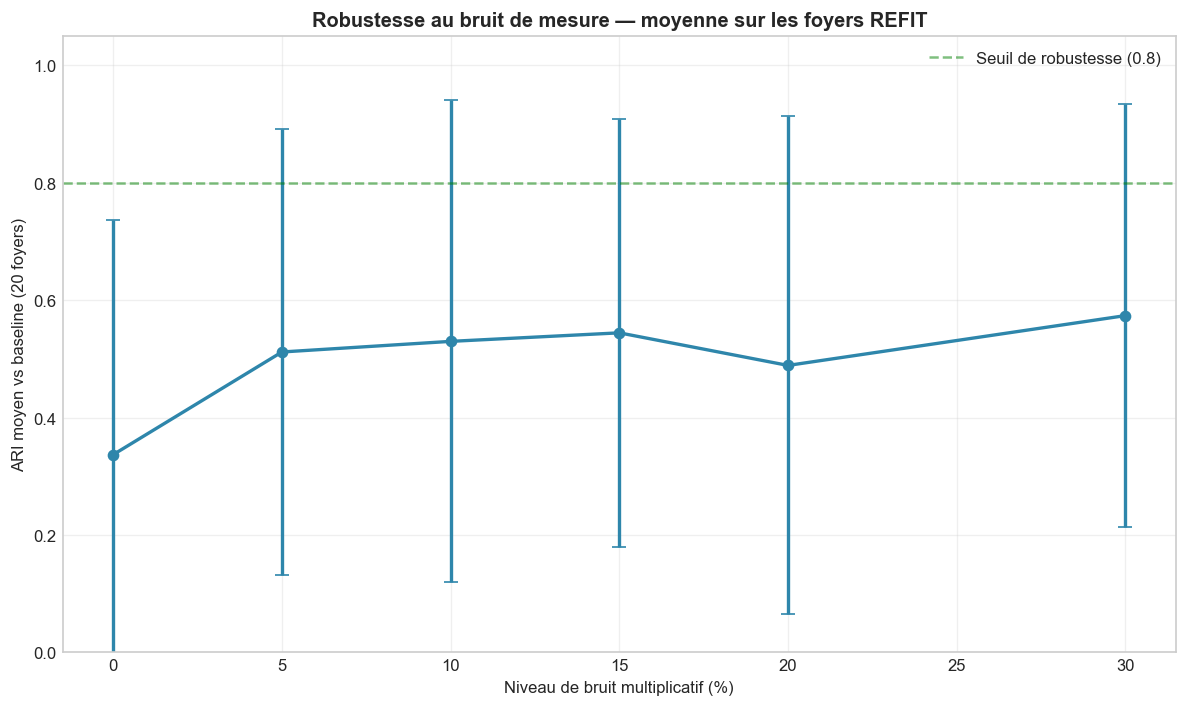

In [ ]:
if not df_noise.empty:
    fig, ax = plt.subplots(figsize=(10, 6))
    mean_by_noise = df_noise.groupby("noise_level")["ari_vs_baseline"].mean()
    std_by_noise = df_noise.groupby("noise_level")["ari_vs_baseline"].std()
    ax.errorbar(mean_by_noise.index * 100, mean_by_noise.values, yerr=std_by_noise.values,
                marker="o", capsize=4, color="#2E86AB", linewidth=2)
    ax.axhline(0.8, color="green", linestyle="--", alpha=0.5, label="Seuil de robustesse (0.8)")
    ax.set_xlabel("Niveau de bruit multiplicatif (%)")
    ax.set_ylabel("ARI moyen vs baseline (20 foyers)")
    ax.set_title("Robustesse au bruit de mesure — moyenne sur les foyers REFIT", fontweight="bold")
    ax.set_ylim(0, 1.05)
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(IMAGES_DIR, "01_robustesse_bruit.png"), dpi=300, bbox_inches="tight")
    plt.show()


## Étape 4 : Dégradation par agrégation (D -> W -> M), Niveau 1

Comparaison par **report du label mensuel/hebdomadaire sur chaque jour qui le compose**, ce
qui permet de calculer un ARI à N constant (nombre de jours), identique à l'esprit de la
section 7.4.1 du TFC (Tab. 27).

In [6]:
aggregation_rows = []

if clean_series and not df_labels_baseline.empty:
    for house_id in refit_house_ids:
        if house_id not in clean_series:
            continue
        k = int(k_by_house.get(house_id, 3))
        baseline = df_labels_baseline[df_labels_baseline["house_id"] == house_id].reset_index(drop=True)
        if baseline.empty:
            continue
        series = clean_series[house_id]

        for freq in ["W", "M"]:
            profile_df = aggregate_to_frequency(series, freq)
            feat_df = compute_features_from_hourly_profiles(profile_df)
            ratio_df = compute_is_weekend_ratio(series, freq)
            feat_df = feat_df.merge(ratio_df, on="period", how="left")

            X_period = StandardScaler().fit_transform(feat_df[FEATURES_FINAL].values)
            labels_period = cluster_with_gmm(X_period, k)
            feat_df["cluster_period"] = labels_period

            # Report du label de période sur chaque jour qui la compose
            if freq == "W":
                period_of_day = series.index.to_series().dt.to_period("W").dt.start_time
            else:
                period_of_day = series.index.to_series().dt.to_period("M").dt.start_time
            day_to_period = period_of_day.dt.date.groupby(series.index.date).first()

            baseline_dates = pd.to_datetime(baseline["date"]).dt.date
            period_lookup = dict(zip(pd.to_datetime(feat_df["period"]).dt.date, feat_df["cluster_period"]))
            # Remonter : jour -> période (même logique que ci-dessus, valable pour W et M)
            day_period_map = {}
            for d in baseline_dates:
                ts = pd.Timestamp(d)
                p = ts.to_period(freq).start_time.date()
                day_period_map[d] = period_lookup.get(p, np.nan)

            broadcasted = baseline_dates.map(day_period_map)
            valid = ~broadcasted.isna()
            if valid.sum() < 10:
                continue

            ari = adjusted_rand_score(baseline["cluster"].values[valid.values], broadcasted[valid].values)
            aggregation_rows.append({"house_id": house_id, "freq": freq, "ari_vs_daily": ari})

df_aggregation = pd.DataFrame(aggregation_rows)
if not df_aggregation.empty:
    pivot_agg = df_aggregation.pivot_table(index="house_id", columns="freq", values="ari_vs_daily")
    print(pivot_agg.round(3).to_string())
    print("\n(Référence UCI, TFC original : ARI journalier vs mensuel = 0.029 -- réétiquetage, pas perte de structure)")


freq          M      W
house_id              
REFIT_1  -0.082  0.406
REFIT_10  0.861  0.969
REFIT_11  0.494  0.017
REFIT_12 -0.018 -0.026
REFIT_13  0.026  0.146
REFIT_15  0.022 -0.012
REFIT_16 -0.003 -0.018
REFIT_17 -0.001 -0.019
REFIT_18  0.110 -0.069
REFIT_19  0.092 -0.061
REFIT_2  -0.028 -0.030
REFIT_20  0.039 -0.040
REFIT_21  0.462  0.847
REFIT_3   0.028  0.042
REFIT_4   1.000 -0.030
REFIT_5  -0.038  0.030
REFIT_6   0.008  0.069
REFIT_7   0.031 -0.048
REFIT_8  -0.062 -0.051
REFIT_9   0.269  0.696

(Référence UCI, TFC original : ARI journalier vs mensuel = 0.029 -- réétiquetage, pas perte de structure)


## Étape 5 : Robustesse du Niveau 2 à la durée d'historique disponible (nouveau test)

On reconstruit les signatures ménages en utilisant seulement les 3, 6 ou 12 premiers mois de
chaque foyer (au lieu des ~2 ans complets), on reclusterise, et on compare à la typologie de
référence (Notebook 04). Ce test simule un déploiement partiel de compteurs intelligents.

In [7]:
from scipy.spatial.distance import cdist

level2_path = os.path.join(RESULTS_DIR, "level2_household_signatures.csv")
df_household_full = pd.read_csv(level2_path) if os.path.exists(level2_path) else pd.DataFrame()

duration_rows = []
DURATIONS_MONTHS = [3, 6, 12]

if not df_household_full.empty and not df_level1_raw.empty:
    full_scaler = StandardScaler().fit(df_household_full[FEATURES_FINAL].values)
    full_labels = df_household_full["cluster"].values
    X_full_scaled = full_scaler.transform(df_household_full[FEATURES_FINAL].values)

    for n_months in DURATIONS_MONTHS:
        truncated_signatures = []
        for _, row in df_household_full.iterrows():
            house_id = row["house_id"]
            df_h = df_level1_raw[df_level1_raw["house_id"] == house_id].sort_values("date")
            cutoff = df_h["date"].min() + pd.DateOffset(months=n_months)
            df_h_truncated = df_h[df_h["date"] < cutoff]
            if df_h_truncated.empty:
                truncated_signatures.append([np.nan] * len(FEATURES_FINAL))
            else:
                truncated_signatures.append(df_h_truncated[FEATURES_FINAL].mean().values)

        X_truncated = np.array(truncated_signatures)
        valid_mask = ~np.isnan(X_truncated).any(axis=1)
        X_truncated_scaled = full_scaler.transform(X_truncated[valid_mask])

        # Assignation au cluster du centroïde le plus proche (référence = clustering complet)
        centroids = np.array([X_full_scaled[full_labels == c].mean(axis=0) for c in np.unique(full_labels)])
        dists = cdist(X_truncated_scaled, centroids)
        assigned_clusters = np.argmin(dists, axis=1)

        agreement_pct = 100 * np.mean(assigned_clusters == full_labels[valid_mask])
        duration_rows.append({
            "n_months": n_months,
            "n_households_valid": int(valid_mask.sum()),
            "pct_agreement_with_full_duration": round(agreement_pct, 1),
        })

df_duration = pd.DataFrame(duration_rows)
if not df_duration.empty:
    print(df_duration.to_string(index=False))


 n_months  n_households_valid  pct_agreement_with_full_duration
        3                  20                              85.0
        6                  20                              75.0
       12                  20                             100.0


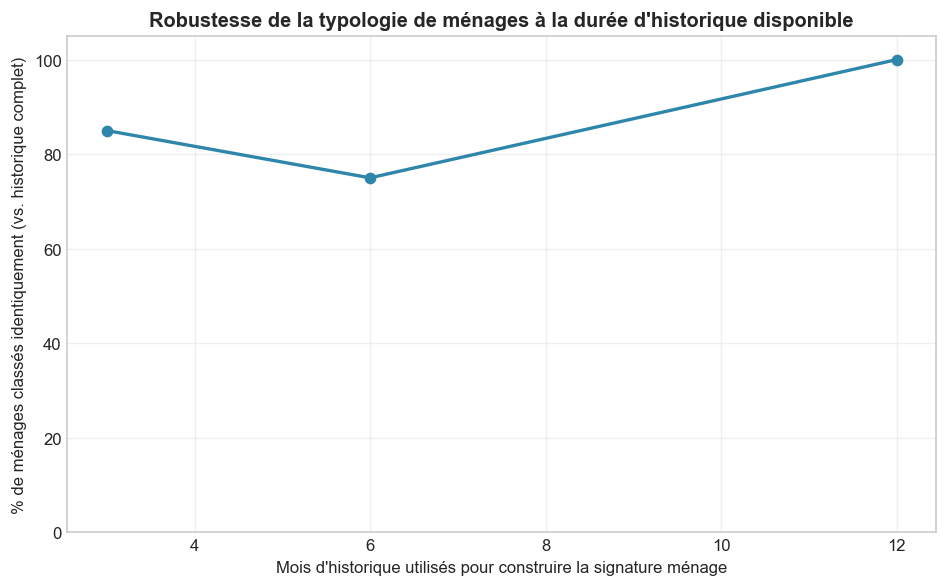

In [ ]:
if not df_duration.empty:
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(df_duration["n_months"], df_duration["pct_agreement_with_full_duration"],
            marker="o", linewidth=2, color="#2E86AB")
    ax.set_xlabel("Mois d'historique utilisés pour construire la signature ménage")
    ax.set_ylabel("% de ménages classés identiquement (vs. historique complet)")
    ax.set_title("Robustesse de la typologie de ménages à la durée d'historique disponible", fontweight="bold")
    ax.set_ylim(0, 105)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(IMAGES_DIR, "02_robustesse_duree_historique.png"), dpi=300, bbox_inches="tight")
    plt.show()


## Étape 6 : Synthèse et sauvegarde

In [9]:
for name, df in [
    ("robustness_ablation_is_weekend.csv", df_ablation if 'df_ablation' in dir() else pd.DataFrame()),
    ("robustness_noise.csv", df_noise if 'df_noise' in dir() else pd.DataFrame()),
    ("robustness_aggregation.csv", df_aggregation if 'df_aggregation' in dir() else pd.DataFrame()),
    ("robustness_level2_duration.csv", df_duration if 'df_duration' in dir() else pd.DataFrame()),
]:
    if not df.empty:
        df.to_csv(os.path.join(RESULTS_DIR, name), index=False)
        print(f"Sauvegardé : results/{name}")


Sauvegardé : results/robustness_ablation_is_weekend.csv
Sauvegardé : results/robustness_noise.csv
Sauvegardé : results/robustness_aggregation.csv
Sauvegardé : results/robustness_level2_duration.csv


## Résumé final

**Fichiers produits :**
- `results/robustness_ablation_is_weekend.csv`
- `results/robustness_noise.csv`
- `results/robustness_aggregation.csv`
- `results/robustness_level2_duration.csv` (nouveau test)
- `images/robustness/01_robustesse_bruit.png`, `02_robustesse_duree_historique.png`

**Ceci conclut le pipeline analytique.** Les tableaux et figures produits par les 6 notebooks
couvrent l'ensemble des résultats nécessaires à la rédaction de l'article (voir
`squelette_article.tex` fourni précédemment, sections Résultats et Discussion).
